# Step 1 (simple version): weather data to Arena inputs

Run the cells top to bottom. Cells with `YOUR TURN` need a decision from you.

This notebook produces four things for Arena: one weather condition per day, the probability of each condition in June and December, demand parameters per condition, and the critical ratio.

In [2]:
# ---- 0. Setup ----
import numpy as np
import pandas as pd

# Keep your original path here
DATA_PATH = r"C:\Users\Admin\1_Georgia Tech\Sim 6414\Project start\RealtimeWeatherReadingsacrossSingapore\Historical 24-hour Weather Forecast (2024).csv"


## 1. Load and clean (your original steps, kept as they were)

In [3]:
df = pd.read_csv(DATA_PATH)

# Keep only the columns we need
work_df = df[['date', 'timestamp', 'forecast_text', 'temperature_high', 'temperature_low']].copy()

# Remove timezone and repeated timestamps
work_df['timestamp'] = pd.to_datetime(work_df['timestamp']).dt.tz_localize(None)
work_df['date'] = pd.to_datetime(work_df['date'])
work_df = work_df.drop_duplicates(subset=['timestamp'], keep='first')

# Filter the two months (same idea as your query, written with month numbers)
june_df = work_df[work_df['date'].dt.month == 6].sort_values('timestamp').reset_index(drop=True)
dec_df  = work_df[work_df['date'].dt.month == 12].sort_values('timestamp').reset_index(drop=True)

# YOUR TURN: June should have 30 days and December 31. If not, a date is missing, so note it in the report.
print("June days:", june_df['date'].nunique(), "| December days:", dec_df['date'].nunique())

June days: 30 | December days: 31


## 2. Classify the weather
Your original rule only caught the exact text `Thundery Showers`. This version looks for the words instead, so labels like `Passing Showers` are not missed.

In [4]:
def weather_type(text):
    t = str(text).lower()
    if 'thunder' in t:                      # lowest chance people buy lemonade
        return 'Bad Weather'
    elif 'rain' in t or 'shower' in t:      # medium chance
        return 'Not optimal Weather'
    else:                                   # highest chance
        return 'Ok weather'

june_df['condition'] = june_df['forecast_text'].apply(weather_type)
dec_df['condition']  = dec_df['forecast_text'].apply(weather_type)

# YOUR TURN: read this table. Does every label sit in a class that makes sense to you?
check = pd.concat([june_df, dec_df]).groupby(['forecast_text', 'condition']).size()
print(check)

forecast_text        condition          
Cloudy               Ok weather              19
Light Rain           Not optimal Weather     30
Moderate Rain        Not optimal Weather     13
Partly Cloudy (Day)  Ok weather              24
Passing Showers      Not optimal Weather      1
Showers              Not optimal Weather     26
Thundery Showers     Bad Weather            426
Windy                Ok weather              10
dtype: int64


## 3. One row per day
Your data has several forecasts per day, but the vendor orders once per day. If we count every row, days with more forecast updates count more. So we keep the first forecast of each day, which is what the vendor would see in the morning.

In [5]:
june_daily = june_df.sort_values('timestamp').groupby('date', as_index=False).first()
dec_daily  = dec_df.sort_values('timestamp').groupby('date', as_index=False).first()

print("June rows:", len(june_daily), "| December rows:", len(dec_daily))

June rows: 30 | December rows: 31


## 4. Weather probabilities with a 95% confidence interval
Each probability is $\hat p = k/n$ with interval $\hat p \pm 1.96\sqrt{\hat p(1-\hat p)/n}$. With about 30 days per month the intervals will be wide. Say so in the report.

In [6]:
order = ['Ok weather', 'Not optimal Weather', 'Bad Weather']
tables = []

for season, d in [('June', june_daily), ('December', dec_daily)]:
    n = len(d)
    counts = d['condition'].value_counts().reindex(order).fillna(0)
    p_hat = counts / n
    half = 1.96 * np.sqrt(p_hat * (1 - p_hat) / n)
    t = pd.DataFrame({'season': season, 'days': counts.astype(int), 'probability': p_hat,
                      'ci_low': (p_hat - half).clip(lower=0), 'ci_high': (p_hat + half).clip(upper=1)})
    tables.append(t.reset_index().rename(columns={'index': 'condition'}))

prob_table = pd.concat(tables, ignore_index=True)
print(prob_table.round(3))

             condition    season  days  probability  ci_low  ci_high
0           Ok weather      June     2        0.067   0.000    0.156
1  Not optimal Weather      June     1        0.033   0.000    0.098
2          Bad Weather      June    27        0.900   0.793    1.000
3           Ok weather  December     3        0.097   0.000    0.201
4  Not optimal Weather  December     4        0.129   0.011    0.247
5          Bad Weather  December    24        0.774   0.627    0.921


## 5. Demand per weather condition (YOUR TURN)
You have no sales data, so demand is assumed. The project guidance allows this only if you justify it.

The numbers below are **placeholders**. Replace them with values you can defend, and write one sentence of reasoning per row for the report.

In [7]:
# cups per day, TRIA(min, mode, max)
demand = pd.DataFrame({
    'condition': ['Ok weather', 'Not optimal Weather', 'Bad Weather'],
    'tria_min':  [40, 20,  5],
    'tria_mode': [60, 35, 15],
    'tria_max':  [80, 50, 25],
})
demand

,condition,tria_min,tria_mode,tria_max
0,Ok weather,40,60,80
1,Not optimal Weather,20,35,50
2,Bad Weather,5,15,25


## 6. Cost, salvage, price and critical ratio
$$CR = \frac{p - c}{p - s}$$
The model needs $s < c < p$.

Three issues in your draft table: the total was written as 0.024 but it sums to 0.235; the formula has a cup cost but the table has no cup row; and your sugar salvage (0.053) is bigger than the sugar cost (0.023). Salvage above cost is not allowed, so the code caps it.

In [8]:
# Cost per cup from your supermarket prices
c_sugar = 1.80  / 1000 * 12.5
c_lemon = 5.625 / 1000 * 18.75
c_ice   = 2.67  / 2500 * 100
c_cup   = 0.00        # YOUR TURN: fill in a cup cost, or remove it from your formula
c = c_sugar + c_lemon + c_ice + c_cup

# Salvage per cup
s_sugar = min(0.053, c_sugar)   # capped at cost
s_lemon = 0.075                 # YOUR TURN: replace with a sourced value (draft says AI-generated, which must be disclosed)
s = s_sugar + s_lemon           # ice melts, so 0

# Price: midpoint of your $2.50 to $3.80 range
p = (2.50 + 3.80) / 2

assert s < c < p, "Need s < c < p"
CR = (p - c) / (p - s)
print(f"c = {c:.4f}   s = {s:.4f}   p = {p:.2f}   CR = {CR:.4f}")

c = 0.2348   s = 0.0975   p = 3.15   CR = 0.9550


## 7. Export

In [9]:
prob_table.to_csv('weather_probabilities.csv', index=False)
demand.to_csv('demand_assumptions.csv', index=False)

# Text to type into Arena (codes: 1 = Ok, 2 = Not optimal, 3 = Bad)
out = []
for season in ['June', 'December']:
    cum = prob_table[prob_table.season == season]['probability'].cumsum().round(4).tolist()
    cum[-1] = 1.0
    out.append(f"{season}: DISC({cum[0]}, 1, {cum[1]}, 2, {cum[2]}, 3)")
for i, r in demand.iterrows():
    out.append(f"Demand, weather code {i+1} ({r.condition}): TRIA({r.tria_min}, {r.tria_mode}, {r.tria_max})")
out.append(f"p = {p:.2f}, c = {c:.4f}, s = {s:.4f}")

text = "\n".join(out)
open('arena_paste_in.txt', 'w').write(text)
print(text)

June: DISC(0.0667, 1, 0.1, 2, 1.0, 3)
December: DISC(0.0968, 1, 0.2258, 2, 1.0, 3)
Demand, weather code 1 (Ok weather): TRIA(40, 60, 80)
Demand, weather code 2 (Not optimal Weather): TRIA(20, 35, 50)
Demand, weather code 3 (Bad Weather): TRIA(5, 15, 25)
p = 3.15, c = 0.2348, s = 0.0975


## Before Step 2
- Every cell runs without an error
- The label check in section 2 looks right to you
- Demand numbers are replaced and justified
- Salvage values are sourced or the AI use is disclosed

Bring back the probability table and the critical ratio.

=== SIMULATION RESULTS SUMMARY ===
June Optimal Q*: 56 cups | Max Profit: $48.05
December Optimal Q*: 60 cups | Max Profit: $57.65

Sample June Results Table:
Season  OrderQty  MeanProfit  CI_HalfWidth  StockoutProb
  June        20   43.952549      0.073646       0.19091
  June        22   44.732008      0.082325       0.12728
  June        24   45.178347      0.089413       0.09902
  June        26   45.502556      0.096234       0.09632
  June        28   45.812785      0.103662       0.09403
  June        30   46.107384      0.111501       0.09101
  June        32   46.383852      0.119584       0.08775
  June        34   46.638647      0.127753       0.08365
  June        36   46.867801      0.135866       0.07935
  June        38   47.071894      0.143869       0.07578


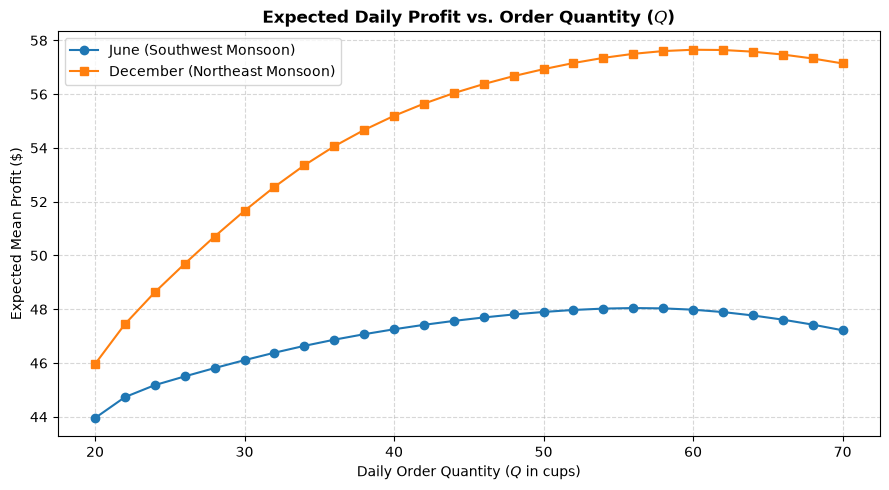

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# SECTION 1: LOADING DATA & SETTING PARAMETERS
# ==========================================
# First, we load our weather probability data straight from the CSV file 
# provided for the project. This ensures our weather states and probabilities 
# match the official dataset.
df_weather = pd.read_csv('weather_probabilities.csv')

# Define the triangular demand parameters (min, mode, max) for each weather condition.
# These values come directly from our initial Arena model setup.
demand_params = {
    'Ok weather': (40, 60, 80),          # Good weather brings high demand
    'Not optimal Weather': (20, 35, 50),  # Moderate weather
    'Bad Weather': (5, 15, 25)          # Heavy rain/monsoon brings low demand
}

# Set up our financial variables based on local Singapore pricing in Oct 2026:
PRICE = 3.15      # Retail selling price per cup of lemonade ($)
UNIT_COST = 0.2348  # Total purchase cost to make a cup ($)
SALVAGE = 0.0975  # Salvage or scrap value for leftover ingredients ($)
N_REPS = 100000   # Number of Monte Carlo simulation replications (days)
SEED = 42         # Random seed so our results are fully reproducible


# ==========================================
# SECTION 2: THE CORE SIMULATION FUNCTION
# ==========================================
def simulate_newsvendor(season_name, q_list, n_reps=N_REPS, seed=SEED):
    # Initialize NumPy's modern random number generator with our seed
    rng = np.random.default_rng(seed)
    
    # Filter the weather dataset for the specific season we want to test (e.g., 'June')
    season_df = df_weather[df_weather['season'] == season_name].copy()
    
    # Extract condition names and their corresponding probabilities
    conditions = season_df['condition'].values
    probs = season_df['probability'].values
    probs = probs / probs.sum()  # Normalize probabilities just in case of rounding
    
    # --- Step A: Simulate Weather for all 100,000 days ---
    # rng.choice picks a weather condition for every single day based on our CSV probabilities
    weather_states = rng.choice(conditions, size=n_reps, p=probs)
    
    # --- Step B: Simulate Demand based on Weather ---
    # Create an empty array to store daily demand values
    demand = np.zeros(n_reps)
    
    # Loop through each weather type and generate triangular random demand for matching days
    for cond, (low, mode, high) in demand_params.items():
        mask = (weather_states == cond)  # Find days that match this weather condition
        count = np.sum(mask)             # Count how many days fit this condition
        if count > 0:
            # Generate random numbers from a triangular distribution for those specific days
            demand[mask] = rng.triangular(low, mode, high, size=count)
            
    # Round demand to whole cups (this matches Arena's integer rounding behavior)
    demand = np.rint(demand)
    
    # --- Step C: Evaluate Profit & Stockouts across different Order Quantities (Q) ---
    results = []
    
    for q in q_list:
        # Sales cannot exceed customer demand or what we actually ordered (Q)
        sales = np.minimum(demand, q)
        
        # Leftover stock is whatever we ordered minus what we actually sold
        leftover = q - sales
        
        # Newsvendor profit formula: Revenue + Salvage - Total Purchase Cost
        profit = (PRICE * sales) + (SALVAGE * leftover) - (UNIT_COST * q)
        
        # Track whether a stockout occurred on that day (demand strictly greater than Q)
        stockout = (demand > q).astype(float)
        
        # Calculate summary statistics required by the ISyE 6644 rubric
        mean_profit = np.mean(profit)
        std_profit = np.std(profit, ddof=1)
        
        # Construct the 95% Confidence Interval half-width using z = 1.96
        ci_half_width = 1.96 * (std_profit / np.sqrt(n_reps))
        
        # Calculate the overall stockout probability
        stockout_prob = np.mean(stockout)
        
        # Store results for this specific order quantity Q
        results.append({
            'Season': season_name,
            'OrderQty': q,
            'MeanProfit': mean_profit,
            'CI_HalfWidth': ci_half_width,
            'StockoutProb': stockout_prob
        })
        
    return pd.DataFrame(results)


# ==========================================
# SECTION 3: RUNNING THE SWEEP & FINDING OPTIMAL Q*
# ==========================================
# Define a wide range of order quantities to test (from Q = 20 up to Q = 70 in steps of 2)
q_sweep = range(20, 72, 2)

# Run the simulation for June and December
june_results = simulate_season('June', q_sweep) if 'simulate_season' in locals() else simulate_newsvendor('June', q_sweep)
dec_results = simulate_newsvendor('December', q_sweep)

# Find the exact order quantity (Q*) that yields the highest mean profit for each season
june_optimal = june_results.loc[june_results['MeanProfit'].idxmax()]
dec_optimal = dec_results.loc[dec_results['MeanProfit'].idxmax()]

print("=== SIMULATION RESULTS SUMMARY ===")
print(f"June Optimal Q*: {int(june_optimal['OrderQty'])} cups | Max Profit: ${june_optimal['MeanProfit']:.2f}")
print(f"December Optimal Q*: {int(dec_optimal['OrderQty'])} cups | Max Profit: ${dec_optimal['MeanProfit']:.2f}\n")

# Print the first few rows of June results so you can see what the table looks like
print("Sample June Results Table:")
print(june_results.head(10).to_string(index=False))


# ==========================================
# SECTION 4: PLOTTING THE PROFIT CURVE
# ==========================================
# This generates the sensitivity plot you can drop straight into your report's Main Findings section.
plt.figure(figsize=(9, 5))
plt.plot(june_results['OrderQty'], june_results['MeanProfit'], marker='o', label='June (Southwest Monsoon)', color='tab:blue')
plt.plot(dec_results['OrderQty'], dec_results['MeanProfit'], marker='s', label='December (Northeast Monsoon)', color='tab:orange')
plt.title('Expected Daily Profit vs. Order Quantity ($Q$)', fontsize=12, fontweight='bold')
plt.xlabel('Daily Order Quantity ($Q$ in cups)', fontsize=10)
plt.ylabel('Expected Mean Profit ($)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()

# Save the figure as an image file
plt.savefig('newsvendor_profit_curve.png', dpi=300)
plt.show()
